# Tugas Praktikum #4: *Asyncio*

## 1. Eksperimen Skala

In [1]:
import asyncio
import statistics
import time

import aiohttp
import matplotlib.pyplot as plt

daftar_paket_banyak = [
    "requests", "numpy", "flask", "aiohttp", "pandas",
    "django", "scipy", "matplotlib", "pillow", "sqlalchemy",
    "fastapi", "beautifulsoup4", "pytest", "pydantic", "httpx",
    "rich", "click", "tqdm", "jupyter", "ipython",
    "sympy", "seaborn", "scikit-learn", "uvicorn", "black",
]

BATAS_KONKURENSI = [1, 3, 5, 10, 20]
ULANGAN = 3

print("Jumlah paket:", len(daftar_paket_banyak))
print("Batas konkurensi yang diuji:", BATAS_KONKURENSI)

Jumlah paket: 25
Batas konkurensi yang diuji: [1, 3, 5, 10, 20]


**Penjelasan.** Daftar berisi 25 nama paket populer di PyPI, sesuai rentang 20 sampai 30 paket pada soal. Nilai `ULANGAN = 3` dipilih sebagai kompromi antara ketahanan terhadap *noise* jaringan dan lamanya eksperimen.

In [ ]:
async def ambil_metadata_paket(session, nama_paket, semaphore):
    url = f"https://pypi.org/pypi/{nama_paket}/json"
    async with semaphore:                      
        try:
            async with session.get(url) as response:
                data = await response.json()
                info = data["info"]
                return {"nama": info["name"], "versi": info["version"], "ok": True}
        except Exception as e:
            return {"nama": nama_paket, "versi": "-", "ok": False, "error": repr(e)}


async def jalankan_sekali(batas):
    semaphore = asyncio.Semaphore(batas)
    timeout = aiohttp.ClientTimeout(total=60)
    mulai = time.perf_counter()
    async with aiohttp.ClientSession(timeout=timeout) as session:
        hasil = await asyncio.gather(
            *[ambil_metadata_paket(session, p, semaphore) for p in daftar_paket_banyak]
        )
    return time.perf_counter() - mulai, hasil

await jalankan_sekali(10)

waktu = {b: [] for b in BATAS_KONKURENSI}
gagal = 0
for putaran in range(ULANGAN):
    for b in BATAS_KONKURENSI:             
        durasi, hasil = await jalankan_sekali(b)
        waktu[b].append(durasi)
        gagal += sum(1 for h in hasil if not h["ok"])
    print(f"Putaran {putaran + 1}/{ULANGAN} selesai")

print("\nTotal request gagal:", gagal)

Putaran 1/3 selesai


Putaran 2/3 selesai


Putaran 3/3 selesai

Total request gagal: 0


**Penjelasan.** `Semaphore` dibuat baru pada setiap percobaan, dan `async with semaphore` membungkus *request* sehingga paling banyak `batas` koneksi aktif pada satu waktu. Kegagalan dicatat (bukan dibiarkan memutus eksperimen) agar waktu yang terukur tetap sebanding antarbatas. Jumlah *request* gagal ditampilkan sebagai pemeriksaan validitas data: bila bukan nol, hasil perlu dibaca dengan hati-hati.

In [3]:
median_waktu = {b: statistics.median(waktu[b]) for b in BATAS_KONKURENSI}
dasar = median_waktu[1]

print(f"{'Batas':>6} {'Median (s)':>11} {'Speedup':>9} {'Efisiensi':>10} {'Perbaikan vs sebelumnya':>25}")
sebelumnya = None
for b in BATAS_KONKURENSI:
    t = median_waktu[b]
    speedup = dasar / t
    if sebelumnya is None:
        perbaikan = "-"
    else:
        perbaikan = f"{(sebelumnya - t) / sebelumnya * 100:6.1f} %"
    efisiensi = speedup / b
    print(f"{b:>6} {t:>11.3f} {speedup:>8.2f}x {efisiensi:>9.0%} {perbaikan:>25}")
    sebelumnya = t

 Batas  Median (s)   Speedup  Efisiensi   Perbaikan vs sebelumnya
     1       0.886     1.00x      100%                         -
     3       0.559     1.59x       53%                    36.9 %
     5       0.497     1.78x       36%                    11.1 %
    10       0.454     1.95x       20%                     8.6 %
    20       0.455     1.95x       10%                    -0.2 %


**Penjelasan.** Kolom *Speedup* adalah waktu pada batas 1 dibagi waktu pada batas tersebut, dan *Efisiensi* adalah *speedup* dibagi batas (100 persen berarti percepatan linear sempurna). Kolom *Perbaikan vs sebelumnya* menunjukkan seberapa besar waktu turun dibanding batas di baris atasnya; nilai kecil berarti penambahan batas sudah memberi manfaat yang sedikit.

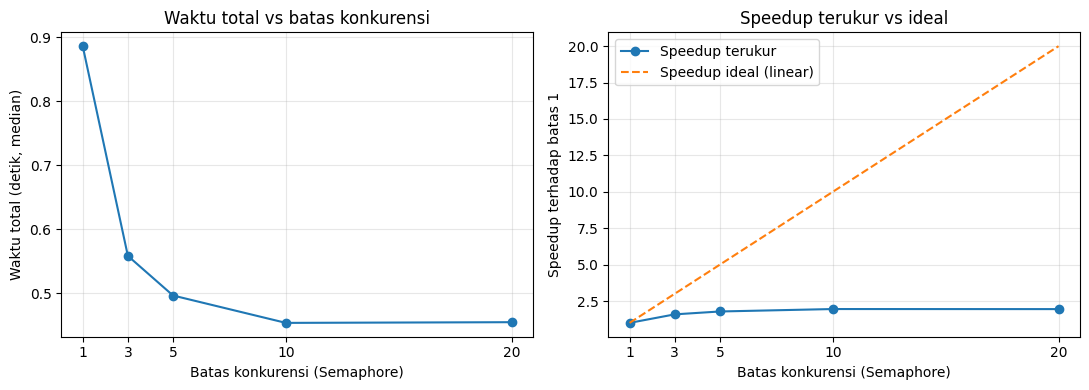

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

ax1.plot(BATAS_KONKURENSI, [median_waktu[b] for b in BATAS_KONKURENSI], marker="o")
ax1.set_xticks(BATAS_KONKURENSI)
ax1.set_xlabel("Batas konkurensi (Semaphore)")
ax1.set_ylabel("Waktu total (detik, median)")
ax1.set_title("Waktu total vs batas konkurensi")
ax1.grid(True, alpha=0.3)

speedup_nyata = [dasar / median_waktu[b] for b in BATAS_KONKURENSI]
ax2.plot(BATAS_KONKURENSI, speedup_nyata, marker="o", label="Speedup terukur")
ax2.plot(BATAS_KONKURENSI, BATAS_KONKURENSI, linestyle="--", label="Speedup ideal (linear)")
ax2.set_xticks(BATAS_KONKURENSI)
ax2.set_xlabel("Batas konkurensi (Semaphore)")
ax2.set_ylabel("Speedup terhadap batas 1")
ax2.set_title("Speedup terukur vs ideal")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

**Penjelasan grafik.** Panel kiri memperlihatkan waktu total; panel kanan membandingkan *speedup* terukur dengan *speedup* ideal (garis putus-putus, yaitu speedup = batas). Jarak antara kedua kurva menunjukkan seberapa besar bagian pekerjaan yang tidak ikut menjadi lebih cepat ketika batas dinaikkan.

In [ ]:
AMBANG_MANFAAT = 0.10   

titik = None
sebelumnya = None
for b in BATAS_KONKURENSI:
    t = median_waktu[b]
    if sebelumnya is not None and (sebelumnya - t) / sebelumnya < AMBANG_MANFAAT:
        titik = b
        break
    sebelumnya = t

if titik is None:
    print(f"Tidak ada titik dengan perbaikan < {AMBANG_MANFAAT:.0%} pada rentang yang diuji.")
else:
    idx = BATAS_KONKURENSI.index(titik)
    print(f"Penambahan batas dari {BATAS_KONKURENSI[idx - 1]} ke {titik} "
          f"hanya memperbaiki waktu kurang dari {AMBANG_MANFAAT:.0%}. "
          f"Titik diminishing returns berada di sekitar batas {titik}.")

print("\nEstimasi fraksi paralel (p) dari Hukum Amdahl, S = 1 / ((1 - p) + p / N):")
for b in BATAS_KONKURENSI[1:]:
    S = dasar / median_waktu[b]
    p = (1 - 1 / S) / (1 - 1 / b)
    print(f"  N = {b:>2}  S = {S:5.2f}x  ->  p = {p:5.2f}")

print("\nJumlah 'gelombang' request (ceil(25 / batas)):")
for b in BATAS_KONKURENSI:
    print(f"  batas {b:>2} -> {-(-len(daftar_paket_banyak) // b)} gelombang")

Penambahan batas dari 5 ke 10 hanya memperbaiki waktu kurang dari 10%. Titik diminishing returns berada di sekitar batas 10.

Estimasi fraksi paralel (p) dari Hukum Amdahl, S = 1 / ((1 - p) + p / N):
  N =  3  S =  1.59x  ->  p =  0.55
  N =  5  S =  1.78x  ->  p =  0.55
  N = 10  S =  1.95x  ->  p =  0.54
  N = 20  S =  1.95x  ->  p =  0.51

Jumlah 'gelombang' request (ceil(25 / batas)):
  batas  1 -> 25 gelombang
  batas  3 -> 9 gelombang
  batas  5 -> 5 gelombang
  batas 10 -> 3 gelombang
  batas 20 -> 2 gelombang


**Analisis.**

Kurva waktu terhadap batas konkurensi hampir selalu menurun tajam di awal lalu mendatar. Pola ini adalah *diminishing returns* yang dijelaskan Hukum Amdahl: *speedup* maksimum dibatasi oleh bagian pekerjaan yang tidak dapat dipercepat dengan menambah konkurensi. Rumusnya S = 1 / ((1 - p) + p / N), dengan p adalah fraksi pekerjaan yang ikut dipercepat dan N adalah faktor percepatan (di sini diwakili batas konkurensi).

Pada eksperimen ini, bagian yang tidak ikut menjadi lebih cepat (1 - p) berasal dari beberapa sumber:

1. **Pembuatan sesi dan jabat tangan awal.** Pembuatan `ClientSession`, resolusi DNS, dan jabat tangan TLS ke `pypi.org` tetap dikerjakan sekali per percobaan, berapa pun batasnya.
2. **Efek gelombang.** Dengan 25 paket, batas 10 dan batas 20 sama-sama membutuhkan beberapa gelombang (lihat keluaran `ceil(25 / batas)`). Menaikkan batas dari 10 ke 20 hanya mengurangi jumlah gelombang sedikit, sedangkan *request* paling lambat tetap menentukan waktu akhir.
3. **Latensi *request* terlama.** Waktu total tidak bisa lebih kecil dari satu *request* tersendiri, sebesar latensi jaringan ke server PyPI. Selain itu server dan CDN di sisi PyPI dapat membatasi laju.
4. ***Event loop* satu *thread*.** Penguraian JSON dan pengelolaan banyak koneksi dikerjakan di satu *thread*, sehingga ikut menjadi bagian serial.

Efisiensi yang terus turun saat batas dinaikkan adalah tanda langsung dari *diminishing returns*: setiap tambahan koneksi menyumbang percepatan yang lebih kecil dari sebelumnya. Karena itu, nilai p yang tercetak pada sel di atas biasanya tidak mencapai 1, dan makin besar N, makin kecil tambahan *speedup* yang diperoleh. Titik yang dicetak sel analisis menunjukkan batas ketika perbaikan turun di bawah 10 persen; membuka lebih dari itu hanya menambah beban koneksi tanpa keuntungan berarti, bahkan berisiko memicu pembatasan laju (*rate limiting*) dari server.

*Catatan:* angka pasti bergantung pada kondisi jaringan saat notebook dijalankan, tetapi bentuk kurvanya (menurun lalu mendatar) konsisten dengan Hukum Amdahl.

## 2. Deteksi *Blocking Call*

In [6]:
import asyncio
import time

SELANG_TARGET = 0.5
t0 = None

def stempel():
    return time.perf_counter() - t0


async def pengukur(selesai):
    terakhir = stempel()
    print(f"[{stempel():5.2f}s] [Pengukur] mulai")
    while not selesai.is_set():
        await asyncio.sleep(SELANG_TARGET)
        sekarang = stempel()
        selang = sekarang - terakhir
        tanda = "  <-- TERLAMBAT, event loop terblokir" if selang > SELANG_TARGET * 1.5 else ""
        print(f"[{sekarang:5.2f}s] [Pengukur] detak (selang {selang:4.2f}s){tanda}")
        terakhir = sekarang


async def korut_async():
    print(f"[{stempel():5.2f}s] [A: asyncio.sleep] mulai")
    await asyncio.sleep(2)
    print(f"[{stempel():5.2f}s] [A: asyncio.sleep] selesai")


async def korut_blocking():
    print(f"[{stempel():5.2f}s] [B: time.sleep] mulai")
    time.sleep(2)                       # BLOCKING: menahan seluruh event loop
    print(f"[{stempel():5.2f}s] [B: time.sleep] selesai")


async def korut_cpu():
    print(f"[{stempel():5.2f}s] [C: CPU-bound] mulai")
    hasil = 1
    for i in range(2, 60001):           # tidak ada await sama sekali
        hasil *= i
    print(f"[{stempel():5.2f}s] [C: CPU-bound] selesai (faktorial 60000 punya {hasil.bit_length()} bit)")

**Penjelasan.** Fungsi `stempel()` memberi waktu relatif sejak eksperimen mulai. `pengukur` menghitung selang nyata antara dua detak dan memberi tanda jika selang lebih dari 1,5 kali target. Faktorial 60000 dipilih agar perhitungan memakan waktu sekitar satu detik, cukup terlihat pada pengukur namun tidak terlalu lama.

In [7]:
async def utama():
    global t0
    t0 = time.perf_counter()
    selesai = asyncio.Event()
    tugas_pengukur = asyncio.create_task(pengukur(selesai))   # dibuat lebih dulu agar start paling awal
    await asyncio.gather(korut_async(), korut_blocking(), korut_cpu())
    total = stempel()
    selesai.set()
    await tugas_pengukur
    print(f"\nWaktu total gather: {total:.2f} detik")

await utama()

[ 0.00s] [Pengukur] mulai
[ 0.00s] [A: asyncio.sleep] mulai
[ 0.00s] [B: time.sleep] mulai


[ 2.00s] [B: time.sleep] selesai
[ 2.00s] [C: CPU-bound] mulai


[ 2.92s] [C: CPU-bound] selesai (faktorial 60000 punya 865809 bit)
[ 2.92s] [Pengukur] detak (selang 2.92s)  <-- TERLAMBAT, event loop terblokir
[ 2.92s] [A: asyncio.sleep] selesai


[ 3.42s] [Pengukur] detak (selang 0.50s)

Waktu total gather: 2.92 detik


**Hasil dan analisis.**

1. **`asyncio.sleep(2)` tidak mengganggu.** Pada baris *log*, coroutine A hanya menyerahkan kendali ke *event loop* lewat `await`, sehingga coroutine lain tetap berjalan selama dua detik itu.
2. **`time.sleep(2)` mengganggu.** Fungsi ini tidak menyerahkan kendali; ia menahan *thread* tempat *event loop* berjalan. Akibatnya detak pengukur yang seharusnya muncul tiap 0,5 detik tertunda sampai `time.sleep` selesai. Selang pada baris bertanda *TERLAMBAT* menunjukkan penundaan itu.
3. **Perhitungan CPU-bound juga mengganggu.** Tidak ada `await` di dalam *loop* faktorial, sehingga *event loop* tidak pernah mendapat kesempatan menjalankan coroutine lain sebelum perhitungan selesai. Ini sama merusaknya dengan `time.sleep`, hanya saja penyebabnya adalah komputasi, bukan menunggu.
4. **Dampak pada total waktu.** Karena B dan C bergantian menahan *thread*, waktu total mendekati penjumlahan durasi keduanya (sekitar 2 detik ditambah lama faktorial); `asyncio.sleep(2)` pada A selesai "di belakang layar" selama B berjalan, sehingga tidak menambah waktu.

**Kesimpulan:** coroutine B (`time.sleep`) dan C (CPU-bound) adalah penyebab terganggunya *event loop*, sedangkan A aman. Sesuai rangkuman materi, *blocking call* menghentikan **seluruh** *event loop*, bukan hanya coroutine yang memanggilnya.

**Perbaikan.** Pekerjaan blocking dapat dipindahkan ke *thread* terpisah dengan `asyncio.to_thread()` agar *event loop* tetap bebas. Sel berikut mengulang percobaan dengan perbaikan tersebut untuk B dan C (pekerjaan C berat, jadi ia berjalan pada *thread* lain sementara pengukur tetap bisa berdetak).

In [8]:
async def korut_blocking_aman():
    print(f"[{stempel():5.2f}s] [B': to_thread(time.sleep)] mulai")
    await asyncio.to_thread(time.sleep, 2)
    print(f"[{stempel():5.2f}s] [B': to_thread(time.sleep)] selesai")


def hitung_faktorial(n):
    hasil = 1
    for i in range(2, n + 1):
        hasil *= i
    return hasil


async def korut_cpu_aman():
    print(f"[{stempel():5.2f}s] [C': to_thread(faktorial)] mulai")
    hasil = await asyncio.to_thread(hitung_faktorial, 60000)
    print(f"[{stempel():5.2f}s] [C': to_thread(faktorial)] selesai ({hasil.bit_length()} bit)")


async def utama_aman():
    global t0
    t0 = time.perf_counter()
    selesai = asyncio.Event()
    tugas_pengukur = asyncio.create_task(pengukur(selesai))
    await asyncio.gather(korut_async(), korut_blocking_aman(), korut_cpu_aman())
    total = stempel()
    selesai.set()
    await tugas_pengukur
    print(f"\nWaktu total gather: {total:.2f} detik")

await utama_aman()

[ 0.00s] [Pengukur] mulai
[ 0.00s] [A: asyncio.sleep] mulai
[ 0.00s] [B': to_thread(time.sleep)] mulai
[ 0.00s] [C': to_thread(faktorial)] mulai


[ 0.51s] [Pengukur] detak (selang 0.51s)


[ 0.98s] [C': to_thread(faktorial)] selesai (865809 bit)
[ 1.01s] [Pengukur] detak (selang 0.50s)


[ 1.51s] [Pengukur] detak (selang 0.50s)


[ 2.00s] [B': to_thread(time.sleep)] selesai
[ 2.00s] [A: asyncio.sleep] selesai
[ 2.01s] [Pengukur] detak (selang 0.50s)

Waktu total gather: 2.00 detik


**Penjelasan.** Setelah B dan C dipindahkan ke *thread* pekerja, pengukur kembali berdetak dengan selang mendekati 0,5 detik, dan waktu total turun karena ketiga pekerjaan benar-benar tumpang tindih. Untuk CPU-bound yang berat, *thread* tetap berbagi *GIL*; solusi yang lebih tepat untuk komputasi besar adalah `ProcessPoolExecutor` (Pertemuan 3). Di sini `to_thread` cukup untuk memperlihatkan bahwa *event loop* tidak lagi tersumbat.

## 3. *Producer*-Multi-*Consumer* dengan Prioritas

In [ ]:
import asyncio
import random

random.seed(7)

JUMLAH_CONSUMER = 3
JUMLAH_ITEM = 12
urutan_diambil = []     


async def producer(queue, jumlah_item):
    for i in range(jumlah_item):
        prioritas = random.randint(1, 3)
        await queue.put((prioritas, i, f"item-{i}"))
        print(f"[Producer] menghasilkan: item-{i} (prioritas {prioritas})")
    for k in range(JUMLAH_CONSUMER):
        await queue.put((99, jumlah_item + k, None))     


async def consumer(queue, nama):
    while True:
        prioritas, nomor, item = await queue.get()
        if item is None:
            queue.task_done()
            break
        urutan_diambil.append(prioritas)
        await asyncio.sleep(random.uniform(0.1, 0.2))     
        print(f"    [{nama}] memproses: {item} (prioritas {prioritas})")
        queue.task_done()


queue = asyncio.PriorityQueue()

await asyncio.gather(
    producer(queue, JUMLAH_ITEM),
    *[consumer(queue, f"Consumer-{i}") for i in range(JUMLAH_CONSUMER)],
)

print("\nPrioritas menurut urutan pengambilan:", urutan_diambil)
assert urutan_diambil == sorted(urutan_diambil), "Urutan prioritas dilanggar!"
print("Verifikasi: semua item diambil dari prioritas 1, lalu 2, lalu 3.")

[Producer] menghasilkan: item-0 (prioritas 2)
[Producer] menghasilkan: item-1 (prioritas 1)
[Producer] menghasilkan: item-2 (prioritas 2)
[Producer] menghasilkan: item-3 (prioritas 3)
[Producer] menghasilkan: item-4 (prioritas 1)
[Producer] menghasilkan: item-5 (prioritas 1)
[Producer] menghasilkan: item-6 (prioritas 3)
[Producer] menghasilkan: item-7 (prioritas 1)
[Producer] menghasilkan: item-8 (prioritas 2)
[Producer] menghasilkan: item-9 (prioritas 3)
[Producer] menghasilkan: item-10 (prioritas 1)
[Producer] menghasilkan: item-11 (prioritas 3)
    [Consumer-1] memproses: item-4 (prioritas 1)
    [Consumer-0] memproses: item-1 (prioritas 1)
    [Consumer-2] memproses: item-5 (prioritas 1)


    [Consumer-1] memproses: item-7 (prioritas 1)
    [Consumer-2] memproses: item-0 (prioritas 2)
    [Consumer-0] memproses: item-10 (prioritas 1)
    [Consumer-1] memproses: item-2 (prioritas 2)


    [Consumer-0] memproses: item-3 (prioritas 3)
    [Consumer-2] memproses: item-8 (prioritas 2)
    [Consumer-0] memproses: item-9 (prioritas 3)
    [Consumer-1] memproses: item-6 (prioritas 3)
    [Consumer-2] memproses: item-11 (prioritas 3)

Prioritas menurut urutan pengambilan: [1, 1, 1, 1, 1, 2, 2, 2, 3, 3, 3, 3]
Verifikasi: semua item diambil dari prioritas 1, lalu 2, lalu 3.


**Penjelasan hasil.**

- *Producer* memasukkan seluruh item lebih dulu (antrean tidak dibatasi `maxsize`, sehingga `put` tidak menunggu). Saat *consumer* mulai berjalan, semua item sudah berada di antrean, dan `PriorityQueue` mengeluarkannya menurut prioritas.
- Daftar `urutan_diambil` terurut menaik (semua prioritas 1, lalu 2, lalu 3), dan pernyataan `assert` membuktikan tidak ada pelanggaran urutan.
- Karena ada 3 *consumer* yang bekerja bersamaan, baris *log* pemrosesan bisa tampak sedikit tidak berurutan (misalnya dua item prioritas 1 selesai dengan urutan berbeda) sebab durasi pemrosesan acak. Yang dijamin adalah **urutan pengambilan dari antrean**, bukan urutan selesainya pemrosesan.
- Sinyal selesai berprioritas 99 memastikan setiap *consumer* baru berhenti setelah seluruh item nyata habis.

*Catatan desain:* prioritas hanya berpengaruh pada item yang **sedang menunggu bersamaan** di antrean. Jika *producer* lebih lambat dari *consumer*, item yang baru masuk akan langsung diambil tanpa sempat "disalip" item lain.

## 4. Refleksi Singkat

*(Maks. 150 kata)*

Untuk kasus I/O-bound, `asyncio` terasa paling efisien setelah konsepnya dipahami, tetapi `threading` paling mudah dimengerti sejak awal. Pada `threading`, kode ditulis hampir sama dengan versi biasa, cukup dibungkus `Thread` atau `ThreadPoolExecutor`. `multiprocessing` paling merepotkan karena data antarproses harus diserialisasi dan debugging lebih sulit; ia lebih cocok untuk CPU-bound, bukan I/O-bound. `asyncio` menuntut pola pikir baru: semua fungsi harus `async`, dan satu `time.sleep` atau pustaka sinkron saja dapat memblokir seluruh *event loop*, seperti terlihat pada Latihan 2. Namun, begitu terbiasa, `asyncio` terbukti ringan dan mudah dikendalikan lewat `Semaphore`, dan percobaan Latihan 1 memperlihatkan puluhan *request* bisa diatur tanpa membuat banyak *thread*. Jadi menurut saya `threading` paling mudah dipahami, sedangkan `asyncio` paling layak dipakai untuk I/O-bound berskala besar.